## Video 3.1.1

# PyTorch tensors and NumPy arrays

Pytorch is extremly similar to NumPy, it is essentially a small upgrade on it to support training AI models in a more convinient way.

PyTorch adds two capabilities needed for deep learning:

1. Tensors can run on accelerators such as NVIDIA CUDA and Intel XPU devices.
2. PyTorch can automatically calculate gradients for training models.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn

print(f"NumPy:  {np.__version__}")
print(f"PyTorch: {torch.__version__}")

## Creating arrays and tensors

The APIs and printed values are intentionally similar. One small difference is the default floating-point type: NumPy normally creates `float64` values, while PyTorch normally uses `float32`, which is faster and smaller for neural networks.

In [ ]:
numpy_array = np.array([[1, 2, 3], [4, 5, 6]], dtype=np.float32)
torch_tensor = torch.tensor([[1, 2, 3], [4, 5, 6]], dtype=torch.float32)

print(numpy_array,"\n")
print(torch_tensor,"\n")

In [ ]:
print("NumPy shape/dtype: ", numpy_array.shape, numpy_array.dtype)
print("PyTorch shape/dtype:", torch_tensor.shape, torch_tensor.dtype)

PyTorch also provides creation functions corresponding closely to NumPy's.
As a general rule code from either can be swaped around with minimal changes.

In [ ]:
print("NumPy zeros:\n", np.zeros((2, 3)))
print("PyTorch zeros:\n", torch.zeros((2, 3)),"\n")

print("Pytorch Zeros like:\n", torch.zeros_like(torch_tensor))

print("\nNumPy range: ", np.arange(0, 10, 2))
print("PyTorch range:", torch.arange(0, 10, 2),"]\n")

print("NumPy random: ", np.random.default_rng(42).random(3))
generator = torch.Generator().manual_seed(42)
print("PyTorch random:", torch.rand(3, generator=generator))

In [ ]:
torch_tensor = torch.tensor([[1, 2, 3], [4, 5, 6]], dtype=torch.float32)

print("Second row:       ", torch_tensor[1])
print("First column:     ", torch_tensor[:, 0])
print("Values above 3:   ", torch_tensor[torch_tensor > 3],"\n")

print("Reshaped to 3 x 2:\n", torch_tensor.reshape(3, 2))

### Tensor operations

In [ ]:
offset = torch.tensor([10, 20, 30])

# The length-3 vector is broadcast across both rows.
print(torch_tensor + offset)

In [ ]:
torch_tensor = torch.tensor([[1, 2, 3], [4, 5, 6]], dtype=torch.float32)

print("Element-wise square:\n", torch_tensor**2,"\n")
print("Mean:", torch_tensor.mean(),"\n")
print("Column sums:", torch_tensor.sum(axis=0),"\n")

weights = torch.tensor([[0.5], [1.0], [-0.5]])
print("Matrix multiplication:\n", torch_tensor @ weights)

### Devices
generally we want to run models on GPU, it is more or less a straight performance win.
While the exact details as to WHY are complicated doing it is easy.

we choose a device to run on (usually at the start of the notebook). and then we move Tensors to that device before we start computing. pytorch would keep all of the results on the GPU for us already

In [ ]:
print("PyTorch device:     ", torch_tensor.device)

In [ ]:
device = (
    torch.accelerator.current_accelerator()
    if torch.accelerator.is_available()
    else torch.device("cpu")
)
print(f"Using: {device}")

### Exchange objects between Numpy - Pytorch

In [54]:
source_array = np.array([1.0, 2.0, 3.0], dtype=np.float32)
shared_tensor = torch.from_numpy(source_array)

shared_tensor[0] = 99
print("NumPy sees the change:", source_array)

back_to_numpy = shared_tensor.numpy()
print("Back to NumPy:       ", back_to_numpy)

back_to_numpy[0]=0
print("NumPy sees the change:", source_array)

NumPy sees the change: [99.  2.  3.]
Back to NumPy:        [99.  2.  3.]
NumPy sees the change: [0. 2. 3.]


In [55]:
accelerated_tensor = torch_tensor.to(device)
result = accelerated_tensor @ weights.to(device)

print("Calculation device:", result.device,"\n")

print(result,"\n")

# NumPy only accepts CPU data, so move the result back first.
result_as_numpy = result.cpu().numpy()
print(result_as_numpy)

Calculation device: xpu:0 

tensor([[1.],
        [4.]], device='xpu:0') 

[[1.]
 [4.]]


## Automatic differentiation
Pytorch can track gradients for us automatically, even when computation is somewhat complex

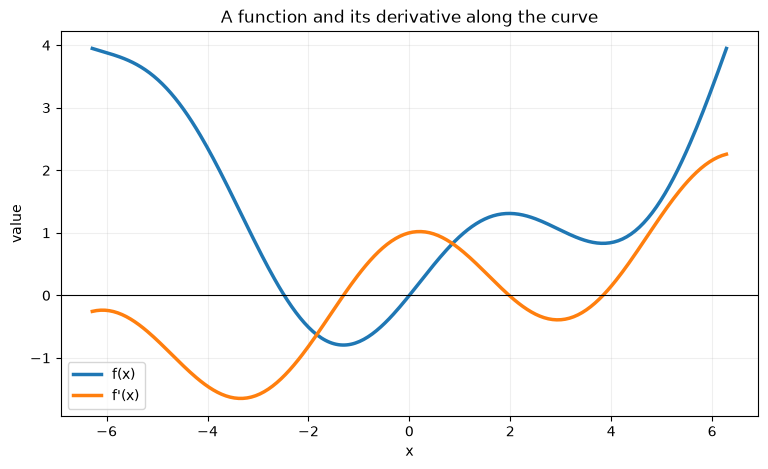

In [56]:
def func1(x):
    return torch.sin(x)

def function(x):
    return func1(x) + 0.1 * x**2

x_curve = torch.linspace(-2 * torch.pi, 2 * torch.pi, 300)
y_curve = torch.vmap(function)(x_curve)

derivative_function = torch.func.grad(function)
dy_dx_curve = torch.vmap(derivative_function)(x_curve)

plt.figure(figsize=(9, 5))
plt.plot(x_curve, y_curve, linewidth=2.5, label=r"f(x)")
plt.plot(x_curve, dy_dx_curve, linewidth=2.5, label=r"f'(x)")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("x")
plt.ylabel("value")
plt.title("A function and its derivative along the curve")
plt.grid(alpha=0.2)
plt.legend()
plt.show()